In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project folder and dataset path
PROJECT_DIR = Path.cwd()
DATA_PATH = Path(r"C:\Users\ry815\Desktop\FraudSentinel-AI\data\PS_20174392719_1491204439457_log.csv")
print("Project folder:", PROJECT_DIR)
print("Dataset exists:", DATA_PATH.exists())

print("Dataset path:",DATA_PATH)

Project folder: C:\Users\ry815\Desktop\FraudSentinel-AI\notebooks
Dataset exists: True
Dataset path: C:\Users\ry815\Desktop\FraudSentinel-AI\data\PS_20174392719_1491204439457_log.csv


In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)


Dataset Shape: (6362620, 11)


In [4]:
# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [5]:
# 3. Data types and non-null counts
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [6]:
# 4. Missing values
print("\nMissing Values:")
display(
    df.isnull().sum()
      .to_frame(name="Missing Values")
      .sort_values("Missing Values", ascending=False)
)


Missing Values:


,Missing Values
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [7]:
# 5. Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [8]:
# 6. Fraud vs non-fraud transactions
print("\nFraud Distribution:")
display(df["isFraud"].value_counts().to_frame("Transaction Count"))



Fraud Distribution:


,Transaction Count
isFraud,
0,6354407
1,8213


In [9]:
# 7. Fraud percentage
print("\nFraud Percentage:")
display(
    (df["isFraud"].value_counts(normalize=True) * 100)
    .round(3)
    .to_frame("Percentage")
)


Fraud Percentage:


,Percentage
isFraud,
0,99.871
1,0.129


In [10]:
# Count legitimate and fraudulent transactions
fraud_counts = df["isFraud"].value_counts().sort_index()

print("Legitimate transactions (0):", fraud_counts.get(0, 0))
print("Fraudulent transactions (1):", fraud_counts.get(1, 0))

# Calculate imbalance ratio
if 0 in fraud_counts.index and 1 in fraud_counts.index:
    imbalance_ratio = fraud_counts[0] / fraud_counts[1]
    print(f"Class imbalance ratio: {imbalance_ratio:.1f}:1")

Legitimate transactions (0): 6354407
Fraudulent transactions (1): 8213
Class imbalance ratio: 773.7:1


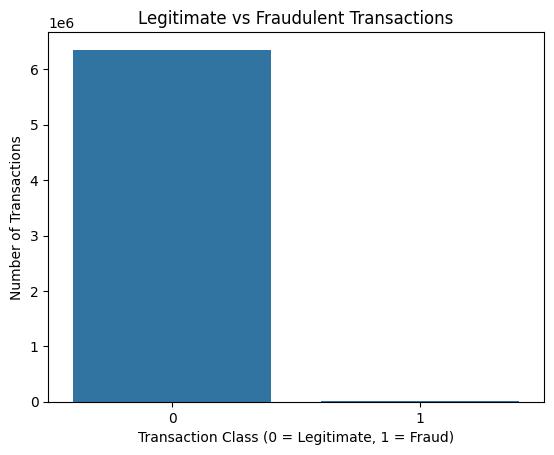

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="isFraud")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [12]:
# Count transactions by type and fraud status
type_fraud = pd.crosstab(
    df["type"],
    df["isFraud"],
    margins=True
)

type_fraud.columns = [
    "Legitimate" if col == 0 else "Fraud" if col == 1 else "Total"
    for col in type_fraud.columns
]

display(type_fraud)

,Legitimate,Fraud,Total
type,,,
CASH_IN,1399284,0,1399284
CASH_OUT,2233384,4116,2237500
DEBIT,41432,0,41432
PAYMENT,2151495,0,2151495
TRANSFER,528812,4097,532909
All,6354407,8213,6362620


In [13]:
# Calculate fraud rate for each transaction type
fraud_by_type = (
    df.groupby("type")
      .agg(
          Total_Transactions=("isFraud", "size"),
          Fraud_Transactions=("isFraud", "sum")
      )
)

fraud_by_type["Fraud_Rate_Percent"] = (
    fraud_by_type["Fraud_Transactions"]
    / fraud_by_type["Total_Transactions"] * 100
).round(3)

display(
    fraud_by_type.sort_values(
        "Fraud_Rate_Percent",
        ascending=False
    )
)

,Total_Transactions,Fraud_Transactions,Fraud_Rate_Percent
type,,,
TRANSFER,532909,4097,0.769
CASH_OUT,2237500,4116,0.184
CASH_IN,1399284,0,0.000
DEBIT,41432,0,0.000
PAYMENT,2151495,0,0.000


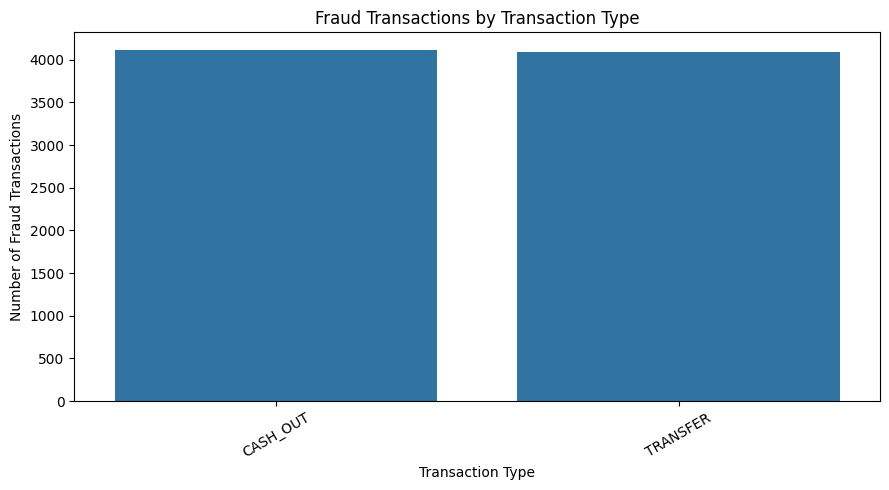

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df[df["isFraud"] == 1],
    x="type",
    order=df[df["isFraud"] == 1]["type"].value_counts().index
)

plt.title("Fraud Transactions by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Fraud Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [15]:
# Compare transaction amounts by fraud status
amount_summary = df.groupby("isFraud")["amount"].agg(
    ["count", "mean", "median", "min", "max"]
)

amount_summary.index = ["Legitimate", "Fraud"]
display(amount_summary.round(2))

,count,mean,median,min,max
Legitimate,6354407,178197.04,74684.72,0.01,92445516.64
Fraud,8213,1467967.30,441423.44,0.00,10000000.00


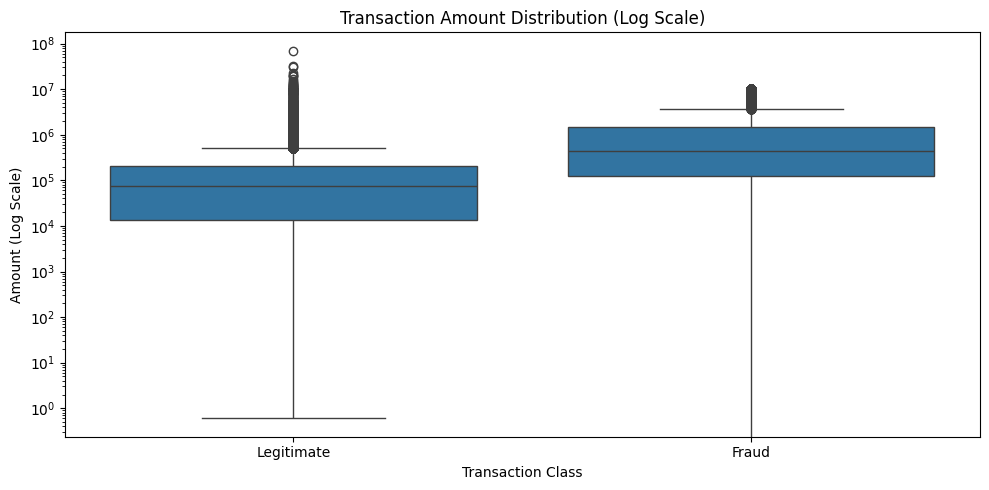

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep all fraud transactions and sample legitimate transactions
fraud_df = df[df["isFraud"] == 1]
legit_sample = df[df["isFraud"] == 0].sample(
    n=min(50000, (df["isFraud"] == 0).sum()),
    random_state=42
)

plot_df = pd.concat([legit_sample, fraud_df])

plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df, x="isFraud", y="amount")
plt.yscale("log")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Amount Distribution (Log Scale)")
plt.xlabel("Transaction Class")
plt.ylabel("Amount (Log Scale)")
plt.tight_layout()
plt.show()

In [17]:
# Summarize fraud transactions
fraud_analysis = (
    df[df["isFraud"] == 1]
    .groupby("type")
    .agg(
        Fraud_Count=("isFraud", "size"),
        Average_Amount=("amount", "mean"),
        Median_Amount=("amount", "median"),
        Total_Amount=("amount", "sum")
    )
    .sort_values("Fraud_Count", ascending=False)
)

display(fraud_analysis.round(2))

,Fraud_Count,Average_Amount,Median_Amount,Total_Amount
type,,,,
CASH_OUT,4116,1455102.59,435516.90,5.989202e+09
TRANSFER,4097,1480891.67,445705.76,6.067213e+09


In [18]:
# Create features without changing the original dataset
df_model = df.copy()

# Sender's balance change
df_model["origin_balance_change"] = (
    df_model["oldbalanceOrg"] - df_model["newbalanceOrig"]
)

# Receiver's balance change
df_model["destination_balance_change"] = (
    df_model["newbalanceDest"] - df_model["oldbalanceDest"]
)

# Difference between transaction amount and sender's balance change
df_model["origin_error"] = (
    df_model["origin_balance_change"] - df_model["amount"]
)

# Difference between transaction amount and receiver's balance change
df_model["destination_error"] = (
    df_model["destination_balance_change"] - df_model["amount"]
)

display(
    df_model[
        [
            "amount",
            "oldbalanceOrg",
            "newbalanceOrig",
            "origin_balance_change",
            "origin_error",
            "destination_balance_change",
            "destination_error",
            "isFraud"
        ]
    ].head()
)

,amount,oldbalanceOrg,newbalanceOrig,origin_balance_change,origin_error,destination_balance_change,destination_error,isFraud
0,9839.64,170136.0,160296.36,9839.64,1.455192e-11,0.0,-9839.64,0
1,1864.28,21249.0,19384.72,1864.28,-1.136868e-12,0.0,-1864.28,0
2,181.00,181.0,0.00,181.00,0.000000e+00,0.0,-181.00,1
3,181.00,181.0,0.00,181.00,0.000000e+00,-21182.0,-21363.00,1
4,11668.14,41554.0,29885.86,11668.14,0.000000e+00,0.0,-11668.14,0


In [19]:
# Count each transaction type
print("Transaction types:")
display(df_model["type"].value_counts().to_frame("count"))

# Fraud rate by transaction type
type_rates = (
    df_model.groupby("type")["isFraud"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "total_transactions",
        "sum": "fraud_transactions",
        "mean": "fraud_rate"
    })
)

type_rates["fraud_rate_percent"] = (
    type_rates["fraud_rate"] * 100
).round(3)

display(type_rates.drop(columns="fraud_rate"))

Transaction types:


,count
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432


,total_transactions,fraud_transactions,fraud_rate_percent
type,,,
CASH_IN,1399284,0,0.000
CASH_OUT,2237500,4116,0.184
DEBIT,41432,0,0.000
PAYMENT,2151495,0,0.000
TRANSFER,532909,4097,0.769


In [20]:
new_features = [
    "origin_balance_change",
    "destination_balance_change",
    "origin_error",
    "destination_error"
]

print("Missing values in new features:")
display(df_model[new_features].isnull().sum())
print("-"*20)
print("Infinite values in new features:")
display(
    np.isinf(df_model[new_features]).sum()
)

Missing values in new features:


origin_balance_change         0
destination_balance_change    0
origin_error                  0
destination_error             0
dtype: int64

--------------------
Infinite values in new features:


origin_balance_change         0
destination_balance_change    0
origin_error                  0
destination_error             0
dtype: int64

In [21]:
# Inspect all columns
print("Columns in dataset:")
print(df_model.columns.tolist())

print("\nDataset shape:", df_model.shape)

print("\nTransaction types:")
print(df_model["type"].unique())

print("\nStep range:")
print(df_model["step"].min(), "to", df_model["step"].max())

Columns in dataset:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'origin_balance_change', 'destination_balance_change', 'origin_error', 'destination_error']

Dataset shape: (6362620, 15)

Transaction types:
['PAYMENT' 'TRANSFER' 'CASH_OUT' 'DEBIT' 'CASH_IN']

Step range:
1 to 743


In [22]:
# Define target
TARGET = "isFraud"

# Select initial predictive features
FEATURES = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "origin_balance_change",
    "destination_balance_change",
    "origin_error",
    "destination_error"
]

X = df_model[FEATURES].copy()
y = df_model[TARGET].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Feature matrix shape: (6362620, 11)
Target shape: (6362620,)


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,origin_balance_change,destination_balance_change,origin_error,destination_error
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,9839.64,0.0,1.455192e-11,-9839.64
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,1864.28,0.0,-1.136868e-12,-1864.28
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,181.00,0.0,0.000000e+00,-181.00
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,181.00,-21182.0,0.000000e+00,-21363.00
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,11668.14,0.0,0.000000e+00,-11668.14


In [23]:
# Sort rows chronologically
df_sorted = df_model.sort_values("step").reset_index(drop=True)

# Use earlier transactions for training and later transactions for testing
split_idx = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_idx].copy()
test_df = df_sorted.iloc[split_idx:].copy()

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()

X_test = test_df[FEATURES].copy()
y_test = test_df[TARGET].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining fraud rate (%):", round(y_train.mean() * 100, 4))
print("Testing fraud rate (%):", round(y_test.mean() * 100, 4))

print("\nTraining step range:", train_df["step"].min(), "-", train_df["step"].max())
print("Testing step range:", test_df["step"].min(), "-", test_df["step"].max())

Training rows: 5090096
Testing rows: 1272524

Training fraud rate (%): 0.0778
Testing fraud rate (%): 0.3343

Training step range: 1 - 355
Testing step range: 355 - 743


In [24]:
# Use unique time steps to avoid splitting one step across train and test
unique_steps = np.sort(df_model["step"].unique())
cutoff_idx = int(len(unique_steps) * 0.8)
cutoff_step = unique_steps[cutoff_idx]

train_df = df_model[df_model["step"] < cutoff_step].copy()
test_df = df_model[df_model["step"] >= cutoff_step].copy()

X_train = train_df[FEATURES].copy()
y_train = train_df["isFraud"].copy()

X_test = test_df[FEATURES].copy()
y_test = test_df["isFraud"].copy()

print("Cutoff step:", cutoff_step)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training step range:", train_df["step"].min(), "-", train_df["step"].max())
print("Testing step range:", test_df["step"].min(), "-", test_df["step"].max())
print("Training fraud rate (%):", round(y_train.mean() * 100, 4))
print("Testing fraud rate (%):", round(y_test.mean() * 100, 4))
print("Fraud cases in test:", int(y_test.sum()))

Cutoff step: 595
Training rows: 6239040
Testing rows: 123580
Training step range: 1 - 594
Testing step range: 595 - 743
Training fraud rate (%): 0.1051
Testing fraud rate (%): 1.3384
Fraud cases in test: 1654


In [25]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

numeric_features = [
    "step", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest",
    "origin_balance_change", "destination_balance_change",
    "origin_error", "destination_error"
]

categorical_features = ["type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor ready.")

Preprocessor ready.


In [26]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        random_state=42
    ))
])

baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [27]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("PR-AUC / Average Precision:", round(average_precision_score(y_test, y_proba), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

Confusion Matrix:
[[110112  11814]
 [    10   1644]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95    121926
           1       0.12      0.99      0.22      1654

    accuracy                           0.90    123580
   macro avg       0.56      0.95      0.58    123580
weighted avg       0.99      0.90      0.94    123580

PR-AUC / Average Precision: 0.7813
ROC-AUC: 0.9892


In [28]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
import pandas as pd
import numpy as np

# Split training period chronologically into fit and validation periods
train_steps = np.sort(train_df["step"].unique())
cut_idx = int(len(train_steps) * 0.8)
validation_start_step = train_steps[cut_idx]

fit_df = train_df[train_df["step"] < validation_start_step].copy()
val_df = train_df[train_df["step"] >= validation_start_step].copy()

X_fit = fit_df[FEATURES]
y_fit = fit_df["isFraud"]

X_val = val_df[FEATURES]
y_val = val_df["isFraud"]

print("Fit rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Validation fraud cases:", int(y_val.sum()))
print("Validation start step:", validation_start_step)

Fit rows: 6032860
Validation rows: 206180
Validation fraud cases: 1244
Validation start step: 476


In [29]:
validation_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        random_state=42
    ))
])

validation_model.fit(X_fit, y_fit)

val_probabilities = validation_model.predict_proba(X_val)[:, 1]

print("Validation model trained!")

Validation model trained!


In [30]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

# Align precision and recall with available thresholds
threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precision[:-1],
    "recall": recall[:-1]
})

# Focus on thresholds detecting at least 90% of validation fraud
candidates = threshold_results[
    threshold_results["recall"] >= 0.90
].sort_values("precision", ascending=False)

display(candidates.head(10).round(4))

,threshold,precision,recall
199118,0.6585,0.1587,0.9003
199117,0.6585,0.1586,0.9003
199116,0.6584,0.1586,0.9003
199115,0.6583,0.1586,0.9003
199114,0.6583,0.1586,0.9003
199113,0.6581,0.1586,0.9003
199112,0.6580,0.1585,0.9003
199111,0.6580,0.1585,0.9003
199104,0.6575,0.1585,0.9011
199110,0.6580,0.1585,0.9003


In [31]:
# Display thresholds with full decimal precision
print("Top candidate thresholds:")

display(
    candidates.head(10).style.format({
        "threshold": "{:.8f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}"
    })
)

print("\nThreshold range:")
print("Minimum:", thresholds.min())
print("Maximum:", thresholds.max())

Top candidate thresholds:


,threshold,precision,recall
199118,0.65848165,0.1587,0.9003
199117,0.65846498,0.1586,0.9003
199116,0.65837976,0.1586,0.9003
199115,0.65826225,0.1586,0.9003
199114,0.65826132,0.1586,0.9003
199113,0.65809509,0.1586,0.9003
199112,0.65803888,0.1585,0.9003
199111,0.65796631,0.1585,0.9003
199104,0.65747269,0.1585,0.9011
199110,0.65795577,0.1585,0.9003



Threshold range:
Minimum: 7.237790696222526e-69
Maximum: 1.0


In [32]:
best_row = candidates.iloc[0]
best_threshold = float(best_row["threshold"])

print("Selected threshold:", best_threshold)
print("Validation precision:", round(best_row["precision"], 4))
print("Validation recall:", round(best_row["recall"], 4))

Selected threshold: 0.658481654497512
Validation precision: 0.1587
Validation recall: 0.9003


In [33]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# Use the final baseline model already trained on training data
test_probabilities = baseline_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("PR-AUC:", round(
    average_precision_score(y_test, test_probabilities), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))

Confusion Matrix:
[[115304   6622]
 [   111   1543]]

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.95      0.97    121926
       Fraud       0.19      0.93      0.31      1654

    accuracy                           0.95    123580
   macro avg       0.59      0.94      0.64    123580
weighted avg       0.99      0.95      0.96    123580

PR-AUC: 0.7813
ROC-AUC: 0.9892


In [34]:
import pandas as pd

# Get feature names after preprocessing
feature_names = baseline_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = baseline_model.named_steps[
    "classifier"
].coef_[0]

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute_Importance"] = (
    feature_importance["Coefficient"].abs()
)

# Show the 15 strongest signals
feature_importance = feature_importance.sort_values(
    by="Absolute_Importance",
    ascending=False
)

display(feature_importance.head(15).round(4))

,Feature,Coefficient,Absolute_Importance
10,cat__type_CASH_IN,-31.9003,31.9003
13,cat__type_PAYMENT,-29.4448,29.4448
14,cat__type_TRANSFER,25.8116,25.8116
11,cat__type_CASH_OUT,24.1108,24.1108
12,cat__type_DEBIT,-13.9143,13.9143
7,num__destination_balance_change,-2.9305,2.9305
8,num__origin_error,2.9043,2.9043
2,num__oldbalanceOrg,2.6028,2.6028
6,num__origin_balance_change,2.5761,2.5761
3,num__newbalanceOrig,2.4496,2.4496


In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# 1. Use only features available before the transaction
PRE_TRANSACTION_FEATURES = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg"
]

X_train_pre = X_train[PRE_TRANSACTION_FEATURES].copy()
X_test_pre = X_test[PRE_TRANSACTION_FEATURES].copy()

# 2. Define preprocessing for these features
preprocessor_pre = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            ["step", "amount", "oldbalanceOrg"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            ["type"]
        )
    ]
)

# 3. Train the pre-transaction model
pre_transaction_model = Pipeline([
    ("preprocessor", preprocessor_pre),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        random_state=42
    ))
])

pre_transaction_model.fit(X_train_pre, y_train)

# 4. Evaluate on the same test rows
pre_probabilities = pre_transaction_model.predict_proba(
    X_test_pre
)[:, 1]

pre_predictions = (pre_probabilities >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, pre_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    pre_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_test, pre_probabilities), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, pre_probabilities), 4)
)

In [ ]:
from sklearn.metrics import precision_recall_curve
import pandas as pd

# Use the same chronological validation split created earlier
X_fit_pre = X_fit[PRE_TRANSACTION_FEATURES].copy()
X_val_pre = X_val[PRE_TRANSACTION_FEATURES].copy()

# Train using only the fitting portion of the training period
pre_validation_model = clone(pre_transaction_model)
pre_validation_model.fit(X_fit_pre, y_fit)

# Predict fraud probabilities on validation data
val_pre_probabilities = pre_validation_model.predict_proba(
    X_val_pre
)[:, 1]

# Calculate precision and recall at different thresholds
pre_precision, pre_recall, pre_thresholds = (
    precision_recall_curve(y_val, val_pre_probabilities)
)

pre_threshold_results = pd.DataFrame({
    "threshold": pre_thresholds,
    "precision": pre_precision[:-1],
    "recall": pre_recall[:-1]
})

# Keep thresholds with at least 90% recall
pre_candidates = pre_threshold_results[
    pre_threshold_results["recall"] >= 0.90
].sort_values(
    by=["precision", "recall"],
    ascending=[False, False]
)

display(pre_candidates.head(10).round(4))

In [ ]:
print("Candidate columns:", pre_candidates.columns.tolist())

best_pre_row = pre_candidates.iloc[0]

print("\nSelected threshold:", best_pre_row["threshold"])
print("Validation precision:", best_pre_row["precision"])
print("Validation recall:", best_pre_row["recall"])

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# Predict probabilities on the test set
pre_test_probabilities = pre_transaction_model.predict_proba(
    X_test_pre
)[:, 1]

# Apply the threshold selected using validation data
best_pre_threshold = float(best_pre_row["threshold"])

pre_test_predictions = (
    pre_test_probabilities >= best_pre_threshold
).astype(int)

print("Selected threshold:", round(best_pre_threshold, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pre_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    pre_test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_test, pre_test_probabilities), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, pre_test_probabilities), 4)
)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Use a reproducible sample of the training data
# Keep all fraud cases and sample a portion of legitimate cases
fraud_train = train_df[train_df["isFraud"] == 1]
legit_train = train_df[train_df["isFraud"] == 0].sample(
    n=min(200_000, (train_df["isFraud"] == 0).sum()),
    random_state=42
)

rf_train = pd.concat(
    [fraud_train, legit_train],
    axis=0
).sample(frac=1, random_state=42)

X_rf_train = rf_train[PRE_TRANSACTION_FEATURES]
y_rf_train = rf_train["isFraud"]

# One-hot encode transaction type
X_rf_train_encoded = pd.get_dummies(
    X_rf_train, columns=["type"], dtype=int
)

X_rf_test_encoded = pd.get_dummies(
    X_test_pre, columns=["type"], dtype=int
).reindex(
    columns=X_rf_train_encoded.columns,
    fill_value=0
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_rf_train_encoded, y_rf_train)

rf_test_probabilities = rf_model.predict_proba(
    X_rf_test_encoded
)[:, 1]

rf_test_predictions = (
    rf_test_probabilities >= 0.5
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_test, rf_test_probabilities), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, rf_test_probabilities), 4)
)

In [ ]:
import pandas as pd

rf_importance = pd.DataFrame({
    "Feature": X_rf_train_encoded.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

display(rf_importance.round(4))

In [ ]:
import matplotlib.pyplot as plt

importance_plot = rf_importance.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_plot["Feature"],
    importance_plot["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("FinGuard AI — Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score

# Pre-transaction features only
numeric_features_pre = ["step", "amount", "oldbalanceOrg"]
categorical_features_pre = ["type"]

preprocessor_pre = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features_pre
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features_pre
    )
])

lr_pre_model = Pipeline([
    ("preprocessor", preprocessor_pre),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        random_state=42
    ))
])

# Fit using the same sampled training rows used for Random Forest
lr_pre_model.fit(X_rf_train, y_rf_train)

# Predict on the same test rows
lr_pre_probabilities = lr_pre_model.predict_proba(
    X_test_pre
)[:, 1]

print("Logistic Regression PR-AUC:",
      round(average_precision_score(y_test, lr_pre_probabilities), 4))

print("Logistic Regression ROC-AUC:",
      round(roc_auc_score(y_test, lr_pre_probabilities), 4))

print("Random Forest PR-AUC:",
      round(average_precision_score(y_test, rf_test_probabilities), 4))

print("Random Forest ROC-AUC:",
      round(roc_auc_score(y_test, rf_test_probabilities), 4))

In [ ]:
from sklearn.metrics import precision_recall_curve
import pandas as pd

# Prepare validation data using the same encoding as training
X_val_rf = pd.get_dummies(
    X_val[PRE_TRANSACTION_FEATURES],
    columns=["type"],
    dtype=int
).reindex(
    columns=X_rf_train_encoded.columns,
    fill_value=0
)

# Predict validation probabilities
rf_val_probabilities = rf_model.predict_proba(
    X_val_rf
)[:, 1]

# Calculate precision and recall for each threshold
rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_val,
    rf_val_probabilities
)

rf_threshold_results = pd.DataFrame({
    "threshold": rf_thresholds,
    "precision": rf_precision[:-1],
    "recall": rf_recall[:-1]
})

# Require at least 90% validation recall
rf_candidates = rf_threshold_results[
    rf_threshold_results["recall"] >= 0.90
].sort_values(
    by=["precision", "recall"],
    ascending=[False, False]
)

display(rf_candidates.head(10).round(4))

In [ ]:
print("Columns:", rf_candidates.columns.tolist())

best_rf_row = rf_candidates.iloc[0]

print("\nSelected threshold:", best_rf_row["threshold"])
print("Validation precision:", best_rf_row["precision"])
print("Validation recall:", best_rf_row["recall"])

print(
    "\nCandidate recall minimum:",
    rf_candidates["recall"].min()
)

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# Use the threshold selected on validation data
best_rf_threshold = float(best_rf_row["threshold"])

# Apply to the held-out test set
rf_test_predictions_tuned = (
    rf_test_probabilities >= best_rf_threshold
).astype(int)

print("Selected threshold:", round(best_rf_threshold, 6))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_predictions_tuned))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_test_predictions_tuned,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print(
    "PR-AUC:",
    round(average_precision_score(y_test, rf_test_probabilities), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, rf_test_probabilities), 4)
)

In [ ]:
# Show validation performance at selected recall targets
for target_recall in [0.70, 0.80, 0.90, 0.95]:
    eligible = rf_threshold_results[
        rf_threshold_results["recall"] >= target_recall
    ]

    if eligible.empty:
        print(f"No threshold found for recall >= {target_recall:.0%}")
        continue

    row = eligible.sort_values(
        "precision", ascending=False
    ).iloc[0]

    print(
        f"Target recall: {target_recall:.0%} | "
        f"Threshold: {row['threshold']:.6f} | "
        f"Precision: {row['precision']:.3f} | "
        f"Recall: {row['recall']:.3f}"
    )

In [ ]:
def summarize_period(name, data):
    print(f"\n{name}")
    print("-" * 40)
    print("Rows:", len(data))
    print("Fraud cases:", int(data["isFraud"].sum()))
    print("Fraud rate (%):", round(data["isFraud"].mean() * 100, 4))
    print("Step range:", data["step"].min(), "to", data["step"].max())

summarize_period("Fit period", fit_df)
summarize_period("Validation period", val_df)
summarize_period("Test period", test_df)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

periods = {
    "Fit": fit_df,
    "Validation": val_df,
    "Test": test_df
}

summary = []

for name, data in periods.items():
    summary.append({
        "Period": name,
        "Rows": len(data),
        "Fraud_Cases": int(data["isFraud"].sum()),
        "Fraud_Rate_Pct": data["isFraud"].mean() * 100,
        "Start_Step": data["step"].min(),
        "End_Step": data["step"].max()
    })

period_summary = pd.DataFrame(summary)

display(period_summary.round(4))

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    period_summary["Period"],
    period_summary["Fraud_Rate_Pct"]
)

plt.title("FinGuard AI — Fraud Rate Across Time Periods")
plt.xlabel("Data Period")
plt.ylabel("Fraud Rate (%)")
plt.tight_layout()
plt.show()

In [ ]:

# FinGuard AI — Compare transaction types across time periods

periods = {
    "Fit": fit_df,
    "Validation": val_df,
    "Test": test_df
}

type_results = []

for period_name, data in periods.items():
    type_summary = (
        data.groupby("type")["isFraud"]
        .agg(Total_Transactions="count", Fraud_Cases="sum")
        .reset_index()
    )

    type_summary["Period"] = period_name
    type_summary["Fraud_Rate_Pct"] = (
        type_summary["Fraud_Cases"]
        / type_summary["Total_Transactions"] * 100
    )

    type_results.append(type_summary)

type_comparison = pd.concat(type_results, ignore_index=True)

display(
    type_comparison.sort_values(["type", "Period"]).round(4)
)


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Use the previously generated Random Forest test probabilities
threshold = 0.9433664635414466

test_analysis = X_test_pre[["type"]].copy()
test_analysis["Actual_Fraud"] = y_test.to_numpy()
test_analysis["Predicted_Fraud"] = (
    rf_test_probabilities >= threshold
).astype(int)

type_performance = []

for transaction_type, group in test_analysis.groupby("type"):
    actual = group["Actual_Fraud"]
    predicted = group["Predicted_Fraud"]

    type_performance.append({
        "Transaction_Type": transaction_type,
        "Total_Transactions": len(group),
        "Actual_Frauds": int(actual.sum()),
        "Detected_Frauds": int(
            ((actual == 1) & (predicted == 1)).sum()
        ),
        "Missed_Frauds": int(
            ((actual == 1) & (predicted == 0)).sum()
        ),
        "False_Alerts": int(
            ((actual == 0) & (predicted == 1)).sum()
        ),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1_Score": f1_score(
            actual, predicted, zero_division=0
        )
    })

type_performance_df = pd.DataFrame(type_performance)
display(type_performance_df.round(4))


In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)

# Use the same threshold and test probabilities
threshold = 0.9433664635414466

y_test_array = y_test.to_numpy()
y_pred_final = (rf_test_probabilities >= threshold).astype(int)

print("Test rows:", len(y_test_array))
print("Probability rows:", len(rf_test_probabilities))
print("Actual frauds:", int(y_test_array.sum()))
print("Predicted frauds:", int(y_pred_final.sum()))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_array, y_pred_final))

print("\nClassification Report:")
print(classification_report(
    y_test_array,
    y_pred_final,
    zero_division=0
))

print("PR-AUC (Average Precision):",
      round(average_precision_score(
          y_test_array, rf_test_probabilities
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_test_array, rf_test_probabilities
      ), 4))


In [ ]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

final_results = pd.DataFrame([{
    "Model": "Random Forest",
    "Features": "Pre-transaction",
    "Test_Transactions": len(y_test_array),
    "Actual_Frauds": int(y_test_array.sum()),
    "Detected_Frauds": int(
        ((y_test_array == 1) & (y_pred_final == 1)).sum()
    ),
    "Missed_Frauds": int(
        ((y_test_array == 1) & (y_pred_final == 0)).sum()
    ),
    "False_Alerts": int(
        ((y_test_array == 0) & (y_pred_final == 1)).sum()
    ),
    "Precision": precision_score(y_test_array, y_pred_final),
    "Recall": recall_score(y_test_array, y_pred_final),
    "F1_Score": f1_score(y_test_array, y_pred_final),
    "PR_AUC": average_precision_score(
        y_test_array, rf_test_probabilities
    ),
    "ROC_AUC": roc_auc_score(
        y_test_array, rf_test_probabilities
    ),
    "Threshold": threshold
}])

display(final_results.round(4))

# Save the evaluation summary
final_results.to_csv(
    "finguard_ai_final_evaluation.csv",
    index=False
)

print("Evaluation summary saved successfully.")


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained Random Forest
feature_importance_df = pd.DataFrame({
    "Feature": X_rf_train_encoded.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    "Importance", ascending=False
)

display(feature_importance_df.round(4))

# Visualize the top features
top_features = feature_importance_df.head(10).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("FinGuard AI — Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

def generate_fraud_alert(transaction, model, feature_columns, threshold):
    """
    transaction: dictionary containing pre-transaction feature values
    model: trained Random Forest model
    feature_columns: columns used during model training
    threshold: selected fraud probability threshold
    """

    transaction_df = pd.DataFrame([transaction])

    # Encode transaction type exactly as during model training
    transaction_encoded = pd.get_dummies(
        transaction_df,
        columns=["type"],
        dtype=int
    ).reindex(columns=feature_columns, fill_value=0)

    fraud_probability = model.predict_proba(
        transaction_encoded
    )[0, 1]

    if fraud_probability >= threshold:
        risk_level = "HIGH"
        decision = "Flag for fraud review"
    elif fraud_probability >= 0.50:
        risk_level = "MEDIUM"
        decision = "Additional verification recommended"
    else:
        risk_level = "LOW"
        decision = "No alert from this model"

    return {
        "transaction_type": transaction["type"],
        "amount": transaction["amount"],
        "fraud_probability_pct": round(
            fraud_probability * 100, 2
        ),
        "risk_level": risk_level,
        "decision": decision
    }


# Example: use an actual test transaction
example_transaction = (
    X_test_pre.iloc[0][PRE_TRANSACTION_FEATURES].to_dict()
)

alert = generate_fraud_alert(
    transaction=example_transaction,
    model=rf_model,
    feature_columns=X_rf_train_encoded.columns,
    threshold=0.9433664635414466
)

display(pd.DataFrame([alert]))


In [ ]:

%pip install shap


In [ ]:

import shap

print("SHAP version:", shap.__version__)


In [ ]:

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Use the same encoded test features as the Random Forest model
# Select a small sample to keep SHAP computation manageable
X_shap = X_rf_test_encoded.iloc[:100].copy()

# Build an explainer for the trained Random Forest
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_values = explainer(X_shap)

print("SHAP calculation completed.")
print("Sample rows explained:", len(X_shap))


In [ ]:

print("X_shap shape:", X_shap.shape)
print("SHAP values shape:", shap_values.values.shape)
print("Feature names:", len(X_shap.columns))
print("SHAP feature names:", len(shap_values.feature_names or []))


In [ ]:

# Rebuild the explainer input with explicit feature names
X_shap = X_rf_test_encoded.iloc[:100].copy()

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_shap, check_additivity=False)

# Explicitly align feature names to the model input columns
shap_values.feature_names = list(X_shap.columns)

print("Input features:", X_shap.shape[1])
print("SHAP features:", shap_values.values.shape[1])


In [ ]:

# Select SHAP values for class 1 (fraud)
shap_fraud = shap_values[:, :, 1]

print("Fraud SHAP shape:", shap_fraud.values.shape)


In [ ]:

shap.plots.bar(shap_fraud, max_display=10)


In [ ]:

# Explain the first transaction in the sample
shap.plots.waterfall(shap_fraud[0], max_display=10)


In [ ]:

# Check the same transaction's Random Forest probability
sample_index = 0

sample_row = X_shap.iloc[[sample_index]]
model_probability = rf_model.predict_proba(sample_row)[0, 1]

print("Model fraud probability:",
      round(model_probability, 6))
print("Model fraud probability (%):",
      round(model_probability * 100, 4))

# Inspect the SHAP output for this transaction
print("SHAP base value:", shap_fraud[sample_index].base_values)
print("SHAP output value:", shap_fraud[sample_index].values.sum()
      + shap_fraud[sample_index].base_values)


In [ ]:

def score_transaction(transaction, model, feature_columns, threshold):
    """
    Score one transaction using pre-transaction features.
    """

    transaction_df = pd.DataFrame([transaction])

    encoded = pd.get_dummies(
        transaction_df,
        columns=["type"],
        dtype=int
    ).reindex(columns=feature_columns, fill_value=0)

    probability = float(model.predict_proba(encoded)[0, 1])

    if probability >= threshold:
        risk_level = "HIGH"
        action = "Flag for human review"
    elif probability >= 0.50:
        risk_level = "MEDIUM"
        action = "Request additional verification"
    else:
        risk_level = "LOW"
        action = "No alert from this model"

    return {
        "transaction_type": transaction["type"],
        "amount": round(float(transaction["amount"]), 2),
        "fraud_probability": round(probability, 6),
        "fraud_probability_pct": round(probability * 100, 2),
        "risk_level": risk_level,
        "recommended_action": action
    }


# Test with the first transaction
result = score_transaction(
    example_transaction,
    rf_model,
    X_rf_train_encoded.columns,
    0.9433664635414466
)

display(pd.DataFrame([result]))


In [ ]:

def explain_transaction(
    transaction,
    model,
    feature_columns,
    threshold,
    explainer
):
    # Encode one transaction using the training feature schema
    transaction_df = pd.DataFrame([transaction])

    encoded = pd.get_dummies(
        transaction_df,
        columns=["type"],
        dtype=int
    ).reindex(columns=feature_columns, fill_value=0)

    probability = float(model.predict_proba(encoded)[0, 1])

    if probability >= threshold:
        risk_level = "HIGH"
        action = "Flag for human review"
    elif probability >= 0.50:
        risk_level = "MEDIUM"
        action = "Request additional verification"
    else:
        risk_level = "LOW"
        action = "No alert from this model"

    # SHAP explanation for the fraud class
    shap_result = explainer(encoded, check_additivity=False)
    fraud_shap = shap_result[0, :, 1]

    explanation = pd.DataFrame({
        "Feature": encoded.columns,
        "SHAP_Value": fraud_shap.values
    })

    explanation["Effect"] = explanation["SHAP_Value"].apply(
        lambda value: (
            "Increases fraud score" if value > 0
            else "Decreases fraud score" if value < 0
            else "No meaningful change"
        )
    )

    explanation = explanation.reindex(
        explanation["SHAP_Value"].abs()
        .sort_values(ascending=False).index
    )

    return {
        "risk_alert": {
            "transaction_type": transaction["type"],
            "amount": float(transaction["amount"]),
            "fraud_probability_pct": round(probability * 100, 2),
            "risk_level": risk_level,
            "recommended_action": action
        },
        "explanation": explanation
    }


result = explain_transaction(
    example_transaction,
    rf_model,
    X_rf_train_encoded.columns,
    0.9433664635414466,
    explainer
)

display(pd.DataFrame([result["risk_alert"]]))
display(result["explanation"].round(4))


In [ ]:

# Create a readable FinGuard AI alert report

alert = result["risk_alert"]
explanation = result["explanation"]

print("=" * 55)
print("             FINGUARD AI — RISK ALERT")
print("=" * 55)

print(f"Transaction Type : {alert['transaction_type']}")
print(f"Amount            : {alert['amount']:,.2f}")
print(f"Fraud Probability : {alert['fraud_probability_pct']:.2f}%")
print(f"Risk Level        : {alert['risk_level']}")
print(f"Recommended Action: {alert['recommended_action']}")

print("\nTop contributing features:")
print("-" * 55)

for _, row in explanation.head(5).iterrows():
    direction = (
        "increased" if row["SHAP_Value"] > 0
        else "decreased" if row["SHAP_Value"] < 0
        else "did not materially change"
    )
    print(
        f"{row['Feature']}: {direction} the model's fraud output "
        f"(SHAP = {row['SHAP_Value']:.4f})"
    )

print("=" * 55)


In [ ]:

import os
import joblib

os.makedirs("models", exist_ok=True)

model_bundle = {
    "model": rf_model,
    "feature_columns": list(X_rf_train_encoded.columns),
    "threshold": 0.9433664635414466,
    "model_name": "Random Forest",
    "features": PRE_TRANSACTION_FEATURES
}

joblib.dump(model_bundle, "models/finguard_model.pkl")

print("Model saved to models/finguard_model.pkl")
